In [3]:

import pandas as pd
from sklearn.datasets import fetch_openml

print("Loading Titanic dataset...")

data = fetch_openml(
    data_id=40945,
    as_frame=True
)

df = data.frame.copy()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())


Loading Titanic dataset...
Dataset loaded successfully!
Dataset shape: (1309, 14)
   pclass survived                                             name     sex  \
0       1        1                    Allen, Miss. Elisabeth Walton  female   
1       1        1                   Allison, Master. Hudson Trevor    male   
2       1        0                     Allison, Miss. Helen Loraine  female   
3       1        0             Allison, Mr. Hudson Joshua Creighton    male   
4       1        0  Allison, Mrs. Hudson J C (Bessie Waldo Daniels)  female   

       age  sibsp  parch  ticket      fare    cabin embarked boat   body  \
0  29.0000      0      0   24160  211.3375       B5        S    2    NaN   
1   0.9167      1      2  113781  151.5500  C22 C26        S   11    NaN   
2   2.0000      1      2  113781  151.5500  C22 C26        S  NaN    NaN   
3  30.0000      1      2  113781  151.5500  C22 C26        S  NaN  135.0   
4  25.0000      1      2  113781  151.5500  C22 C26        S  N

In [4]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Select useful passenger features
X = df[["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]].copy()
y = pd.to_numeric(df["survived"], errors="coerce")

# Remove rows with missing target
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid].astype(int)

numeric_features = ["pclass", "age", "sibsp", "parch", "fare"]
categorical_features = ["sex", "embarked"]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model training complete!")
print("Accuracy:", round(accuracy_score(y_test, predictions) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, predictions))


Model training complete!
Accuracy: 80.15 %

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.84      0.84       162
           1       0.74      0.74      0.74       100

    accuracy                           0.80       262
   macro avg       0.79      0.79      0.79       262
weighted avg       0.80      0.80      0.80       262



In [5]:

new_passenger = pd.DataFrame([{
    "pclass": 3,
    "sex": "female",
    "age": 25,
    "sibsp": 0,
    "parch": 0,
    "fare": 15.0,
    "embarked": "S"
}])

result = model.predict(new_passenger)[0]
probability = model.predict_proba(new_passenger)[0]

print("Titanic Survival Prediction")
print("Result:", "Survived" if result == 1 else "Did not survive")
print("Probability of survival:", round(probability[1] * 100, 2), "%")


Titanic Survival Prediction
Result: Survived
Probability of survival: 57.0 %


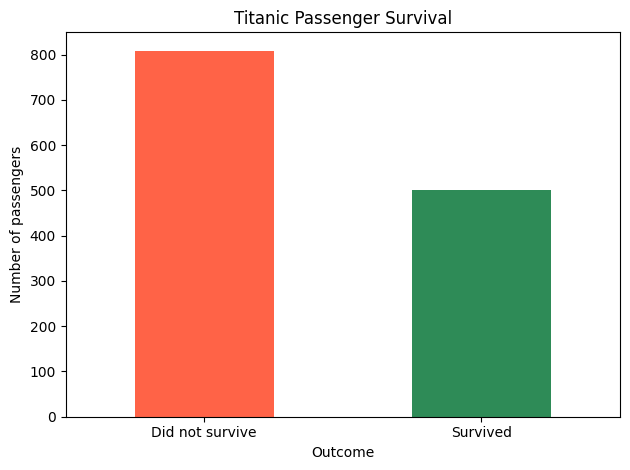

In [6]:

import matplotlib.pyplot as plt

df["survived"] = pd.to_numeric(
    df["survived"], errors="coerce"
)

df.groupby("survived").size().rename({
    0: "Did not survive",
    1: "Survived"
}).plot(kind="bar", color=["tomato", "seagreen"])

plt.title("Titanic Passenger Survival")
plt.xlabel("Outcome")
plt.ylabel("Number of passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
